# NYC Flights 2023: data cleaning case study

**The brief.** A client hands over five raw exports (flights, airlines, airports, planes, weather) and wants a
trustworthy dataset that can be loaded straight into a database.

**The three questions this notebook answers**

1. What is wrong with the data?
2. What was done about each problem?
3. Why was that the right decision?

**How the notebook is organised**

| Step | What happens |
|---|---|
| 1 | Load the five files and take a first look |
| 2 | Audit: measure every data-quality issue and record a decision for each one |
| 3 | Clean each table, with a before/after check |
| 4 | Validate: assertions that prove the cleaned data obeys the rules |
| 5 | Export the cleaned tables and the cleaning log |

The data is real: every flight that left New York City's three airports (JFK, LGA, EWR) in 2023.
Nothing is simulated and no values are invented during cleaning.

## 1. Load and first look

Import the libraries and set up the folder paths. The paths are *relative* to this notebook, so the project runs on any computer.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Show wide tables without cutting columns off
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

# The notebook lives in notebooks/, so the project folder is one level up
PROJECT = Path.cwd().parent
RAW = PROJECT / "data" / "raw"
PROCESSED = PROJECT / "data" / "processed"
IMAGES = PROJECT / "images"

PROCESSED.mkdir(parents=True, exist_ok=True)
IMAGES.mkdir(parents=True, exist_ok=True)

Read the five raw files. `flights.csv` is 45 MB, so it is stored inside a zip file. pandas can read a zip that holds one CSV directly.

In [2]:
airlines_raw = pd.read_csv(RAW / "airlines.csv")
airports_raw = pd.read_csv(RAW / "airports.csv")
planes_raw = pd.read_csv(RAW / "planes.csv")
weather_raw = pd.read_csv(RAW / "weather.csv")
flights_raw = pd.read_csv(RAW / "flights.zip")

# Keep the raw tables in a dictionary so we can loop over them
raw_tables = {
    "airlines": airlines_raw,
    "airports": airports_raw,
    "planes": planes_raw,
    "weather": weather_raw,
    "flights": flights_raw,
}

for name, table in raw_tables.items():
    print(f"{name:9s} {table.shape[0]:>8,} rows  {table.shape[1]:>3} columns")

airlines        14 rows    2 columns
airports     1,255 rows    8 columns
planes       4,840 rows    9 columns
weather     26,207 rows   15 columns
flights    435,352 rows   19 columns


Look at the first rows of each table to see what the values actually look like.

In [3]:
flights_raw.head()

,year,month,day,dep_time,sched_dep_time,dep_delay,arr_time,sched_arr_time,arr_delay,carrier,flight,tailnum,origin,dest,air_time,distance,hour,minute,time_hour
0,2023,1,1,1.0,2038,203.0,328.0,3,205.0,UA,628,N25201,EWR,SMF,367.0,2500.0,20.0,38.0,2023-01-01 20:00:00
1,2023,1,1,18.0,2300,78.0,228.0,135,53.0,DL,393,N830DN,JFK,ATL,108.0,760.0,23.0,0.0,2023-01-01 23:00:00
2,2023,1,1,31.0,2344,47.0,500.0,426,34.0,B6,371,N807JB,JFK,BQN,190.0,1576.0,23.0,44.0,2023-01-01 23:00:00
3,2023,1,1,33.0,2140,173.0,238.0,2352,166.0,B6,1053,N265JB,JFK,CHS,108.0,636.0,21.0,40.0,2023-01-01 21:00:00
4,2023,1,1,36.0,2048,228.0,223.0,2252,211.0,UA,219,N17730,EWR,DTW,80.0,488.0,20.0,48.0,2023-01-01 20:00:00


In [4]:
planes_raw.head()

,tailnum,year,type,manufacturer,model,engines,seats,speed,engine
0,N101DQ,2020.0,Fixed wing multi engine,AIRBUS,A321-211,2,199,0,Turbo-fan
1,N101DU,2018.0,Fixed wing multi engine,C SERIES AIRCRAFT LTD PTNRSP,BD-500-1A10,2,133,0,Turbo-fan
2,N101HQ,2007.0,Fixed wing multi engine,EMBRAER-EMPRESA BRASILEIRA DE,ERJ 170-200 LR,2,80,0,Turbo-fan
3,N101NN,2013.0,Fixed wing multi engine,AIRBUS INDUSTRIE,A321-231,2,379,0,Turbo-fan
4,N102DN,2020.0,Fixed wing multi engine,AIRBUS,A321-211,2,199,0,Turbo-fan


In [5]:
airports_raw.head()

,faa,name,lat,lon,alt,tz,dst,tzone
0,AAF,Apalachicola Regional Airport,29.727501,-85.027496,20.0,-5.0,A,America/New_York
1,AAP,Andrau Airpark,29.722500,-95.588303,79.0,-6.0,A,America/Chicago
2,ABE,Lehigh Valley International Airport,40.652100,-75.440804,393.0,-5.0,A,America/New_York
3,ABI,Abilene Regional Airport,32.411301,-99.681900,1791.0,-6.0,A,America/Chicago
4,ABL,Ambler Airport,67.106300,-157.856989,334.0,-9.0,A,America/Anchorage


In [6]:
weather_raw.head()

,origin,year,month,day,hour,temp,dewp,humid,wind_dir,wind_speed,wind_gust,precip,pressure,visib,time_hour
0,JFK,2023,1,1,0,48.0,48.0,100.0,0.0,0.00000,0.000000,0.0100,1010.2,0.25,2023-01-01 00:00:00
1,JFK,2023,1,1,1,48.2,48.2,100.0,190.0,4.60312,5.297178,0.0100,1009.2,2.50,2023-01-01 01:00:00
2,JFK,2023,1,1,2,49.0,49.0,100.0,190.0,5.75390,6.621473,0.0001,1009.0,0.25,2023-01-01 02:00:00
3,JFK,2023,1,1,3,49.0,49.0,100.0,250.0,5.75390,6.621473,0.0200,1008.0,4.00,2023-01-01 03:00:00
4,JFK,2023,1,1,4,49.0,49.0,100.0,170.0,8.05546,9.270062,0.0001,1007.8,0.75,2023-01-01 04:00:00


In [7]:
airlines_raw.head()

,carrier,name
0,9E,Endeavor Air Inc.
1,AA,American Airlines Inc.
2,AS,Alaska Airlines Inc.
3,B6,JetBlue Airways
4,DL,Delta Air Lines Inc.


### Column types and missing values

For each table: the type pandas chose for every column, how many values are missing, and how many different
values there are. This one small helper function is reused for all five tables.

In [8]:
def profile(table):
    # Return one row per column: its type, missing count, missing % and number of distinct values
    result = pd.DataFrame({
        "dtype": table.dtypes.astype(str),
        "missing": table.isna().sum(),
        "missing_pct": (table.isna().mean() * 100).round(2),
        "distinct": table.nunique(),
    })
    return result

profile(flights_raw)

,dtype,missing,missing_pct,distinct
year,int64,0,0.00,1
month,int64,0,0.00,12
day,int64,0,0.00,31
dep_time,float64,10738,2.47,1365
sched_dep_time,int64,0,0.00,1060
dep_delay,float64,10738,2.47,946
arr_time,float64,11453,2.63,1433
sched_arr_time,int64,0,0.00,1200
arr_delay,float64,12534,2.88,1019
carrier,object,0,0.00,14


**What stands out in flights**

- `dep_time`, `arr_time`, `hour` and `minute` are stored as decimals (`float64`). The raw file holds whole numbers,
  but some rows are blank, and pandas turns a whole-number column with blanks into decimals.
- The delay and time columns have between 10,000 and 13,000 missing values. These need to be understood before
  anything is done with them.
- `year` has only one distinct value, so it carries no information on its own.

In [9]:
profile(planes_raw)

,dtype,missing,missing_pct,distinct
tailnum,object,0,0.00,4840
year,float64,89,1.84,34
type,object,0,0.00,3
manufacturer,object,0,0.00,12
model,object,0,0.00,92
engines,int64,0,0.00,3
seats,int64,0,0.00,44
speed,int64,0,0.00,1
engine,object,0,0.00,4


In [10]:
profile(airports_raw)

,dtype,missing,missing_pct,distinct
faa,object,0,0.00,1255
name,object,0,0.00,1252
lat,float64,0,0.00,1255
lon,float64,0,0.00,1253
alt,float64,0,0.00,860
tz,float64,48,3.82,9
dst,object,48,3.82,4
tzone,object,119,9.48,11


In [11]:
profile(weather_raw)

,dtype,missing,missing_pct,distinct
origin,object,0,0.00,3
year,int64,0,0.00,1
month,int64,0,0.00,12
day,int64,0,0.00,31
hour,int64,0,0.00,24
temp,float64,2,0.01,123
dewp,float64,2,0.01,132
humid,float64,2,0.01,2989
wind_dir,float64,1225,4.67,37
wind_speed,float64,1041,3.97,31


In [12]:
profile(airlines_raw)

,dtype,missing,missing_pct,distinct
carrier,object,0,0.0,14
name,object,0,0.0,14


### Chart 1: where are the missing values?

One bar for every raw column that has at least one missing value.

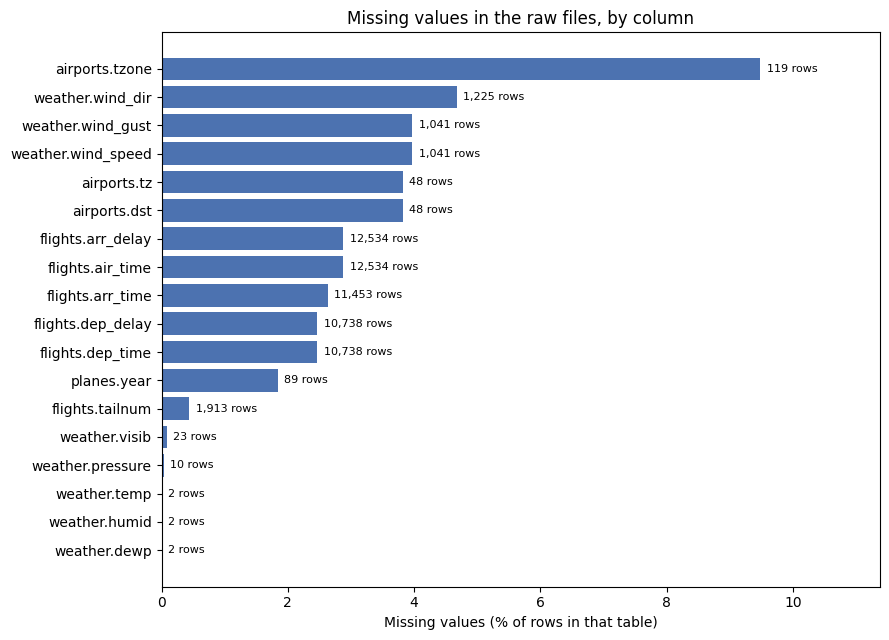

In [13]:
# Collect the missing % of every column in every table
rows = []
for name, table in raw_tables.items():
    for column in table.columns:
        missing_count = table[column].isna().sum()
        if missing_count > 0:
            rows.append({
                "label": f"{name}.{column}",
                "missing": missing_count,
                "missing_pct": missing_count / len(table) * 100,
            })

missing_table = pd.DataFrame(rows).sort_values("missing_pct")

fig, ax = plt.subplots(figsize=(9, 6.5))
bars = ax.barh(missing_table["label"], missing_table["missing_pct"], color="#4C72B0")

# Write the row count next to each bar
for bar, count in zip(bars, missing_table["missing"]):
    ax.text(bar.get_width() + 0.1, bar.get_y() + bar.get_height() / 2, f"{count:,} rows", va="center", fontsize=8)

ax.set_xlabel("Missing values (% of rows in that table)")
ax.set_title("Missing values in the raw files, by column")
ax.set_xlim(0, missing_table["missing_pct"].max() * 1.2)
fig.tight_layout()
fig.savefig(IMAGES / "01_missing_values_raw.png", dpi=150)
plt.show()

## 2. Data-quality audit

Each check below measures one possible problem. The result goes into a list called `audit`, together with the
decision taken. At the end of this section the list becomes the **audit table**, which is also saved as
`cleaning_log.csv`.

Recording the decision next to the measurement means the client can see *what* was changed, *how many rows*
were affected and *why*.

In [14]:
audit = []

def log_issue(table, column, issue, rows_affected, decision):
    # Add one line to the audit table
    audit.append({
        "table": table,
        "column": column,
        "issue": issue,
        "rows_affected": int(rows_affected),
        "decision": decision,
    })

### 2.1 Duplicates and keys

A database table needs a column (or set of columns) that identifies each row. First check for fully duplicated rows, then check the obvious candidate keys.

In [15]:
for name, table in raw_tables.items():
    print(f"{name:9s} fully duplicated rows: {table.duplicated().sum()}")

airlines  fully duplicated rows: 0
airports  fully duplicated rows: 0
planes    fully duplicated rows: 0
weather   fully duplicated rows: 0


flights   fully duplicated rows: 0


In [16]:
# Candidate keys for the lookup tables
print("airlines.carrier unique:", airlines_raw["carrier"].is_unique)
print("airports.faa unique:    ", airports_raw["faa"].is_unique)
print("planes.tailnum unique:  ", planes_raw["tailnum"].is_unique)
print("weather (origin, time_hour) unique:", not weather_raw.duplicated(["origin", "time_hour"]).any())

# Flights has no single id column. Is a combination of columns unique?
natural_key = ["year", "month", "day", "carrier", "flight", "origin", "sched_dep_time"]
print("flights natural key unique:", not flights_raw.duplicated(natural_key).any())

airlines.carrier unique: True
airports.faa unique:     True
planes.tailnum unique:   True
weather (origin, time_hour) unique: True
flights natural key unique: True


No duplicates anywhere, and the lookup tables all have a usable key.

Flights can be identified by seven columns together (date, carrier, flight number, origin, scheduled time), but a
seven-column key is awkward to use in a database. **Decision:** add a simple numbered `flight_id` column.

In [17]:
log_issue("flights", "(all)", "No primary key column; rows are only unique on a 7-column combination",
          len(flights_raw), "Added surrogate key flight_id (1 to N, in the original row order)")
log_issue("all tables", "(all)", "Fully duplicated rows (check)", 0, "None found; no action needed")

### 2.2 Flights: clock times stored as numbers

`dep_time`, `sched_dep_time`, `arr_time` and `sched_arr_time` are clock times written as HHMM numbers:
`517` means 05:17 and `2038` means 20:38. A database cannot sort or subtract these correctly
(for example 600 minus 559 is 41, but the real gap is one minute).

Check the values are valid clock times: minutes must be 0 to 59, and note any use of `2400`.

In [18]:
time_columns = ["dep_time", "sched_dep_time", "arr_time", "sched_arr_time"]

for column in time_columns:
    values = flights_raw[column].dropna()
    bad_minutes = (values % 100 > 59).sum()        # the last two digits are the minutes
    is_2400 = (values == 2400).sum()
    print(f"{column:15s} min={values.min():>6.0f} max={values.max():>6.0f} "
          f"minutes over 59: {bad_minutes}   equal to 2400: {is_2400}")

dep_time        min=     1 max=  2400 minutes over 59: 0   equal to 2400: 27
sched_dep_time  min=   500 max=  2359 minutes over 59: 0   equal to 2400: 0
arr_time        min=     1 max=  2400 minutes over 59: 0   equal to 2400: 198
sched_arr_time  min=     1 max=  2359 minutes over 59: 0   equal to 2400: 0


All minutes are valid. `2400` appears in the two *actual* time columns. It means midnight at the end of the day,
which is 00:00 of the **next** day. A database rejects 24:00 as a time, so it has to be converted.

In [19]:
n_dep_2400 = (flights_raw["dep_time"] == 2400).sum()
n_arr_2400 = (flights_raw["arr_time"] == 2400).sum()

log_issue("flights", "dep_time, sched_dep_time, arr_time, sched_arr_time",
          "Clock times stored as HHMM numbers (517 = 05:17), read as decimals because of blank rows",
          len(flights_raw),
          "Departures converted to full DATETIME columns; arrivals converted to TIME columns")
log_issue("flights", "dep_time", "Value 2400 used for midnight (not a valid clock time)", n_dep_2400,
          "Converted to 00:00 of the next day in actual_dep_datetime")
log_issue("flights", "arr_time", "Value 2400 used for midnight (not a valid clock time)", n_arr_2400,
          "Converted to 00:00:00 in actual_arr_time")

### 2.3 Flights: departures that roll past midnight

The file gives one date per flight (the *scheduled* date) and an actual departure clock time, but no actual
departure date. A flight scheduled for 23:00 that leaves at 00:18 really departed the next day.

The `dep_delay` column lets us test this. If a flight left on its scheduled date, then
`dep_delay` = actual clock time minus scheduled clock time. If the two differ by 1,440 minutes (one full day),
the flight left the next day.

In [20]:
def hhmm_to_minutes(hhmm):
    # Turn an HHMM number into minutes after midnight, e.g. 517 -> 5*60 + 17 = 317
    hours = hhmm // 100       # whole-number division drops the last two digits
    minutes = hhmm % 100      # the remainder is the last two digits
    return hours * 60 + minutes

departed = flights_raw.dropna(subset=["dep_time"])

clock_difference = hhmm_to_minutes(departed["dep_time"]) - hhmm_to_minutes(departed["sched_dep_time"])
unexplained = departed["dep_delay"] - clock_difference

unexplained.value_counts()

0.0       422205
1440.0      2407
1380.0         1
1500.0         1
Name: count, dtype: int64

- For almost all departed flights the difference is 0: delay and clock times agree.
- For about 2,400 flights it is 1,440 minutes: they left the day after their scheduled date.
- Two flights are off by 1,380 and 1,500 minutes, which is one day minus or plus one hour. Look at them:

In [21]:
odd_rows = departed[~unexplained.isin([0, 1440])]
odd_rows[["month", "day", "sched_dep_time", "dep_time", "dep_delay", "carrier", "flight", "origin", "dest"]]

,month,day,sched_dep_time,dep_time,dep_delay,carrier,flight,origin,dest
83757,3,11,2127,755.0,568.0,DL,259,JFK,LAS
371256,11,4,2250,644.0,534.0,9E,1479,JFK,ROC


These two were scheduled on the evening of 11 March and 4 November and left the next morning. Those are exactly
the nights the clocks changed in 2023 (12 March and 5 November). The delay was measured in real elapsed minutes, so
it is one hour shorter or longer than the clock difference. The data is correct; it is a daylight-saving effect.

**Decision:** work out the day offset by rounding `unexplained / 1440` to the nearest whole number. That gives 0
or 1 for every row, including the two clock-change rows.

In [22]:
day_offset_check = (unexplained / 1440).round()
n_next_day = (day_offset_check == 1).sum()
n_dst = len(odd_rows)
print("Day offsets found:", day_offset_check.value_counts().to_dict())

log_issue("flights", "dep_time", "Actual departure was on the day after the scheduled date, but the file has no actual date",
          n_next_day, "Built actual_dep_datetime with the correct date, using dep_delay to detect the day change")
log_issue("flights", "dep_delay", "Delay differs from the clock difference by 1 hour (flights delayed across a daylight-saving change)",
          n_dst, "Kept as is; the delay is correct elapsed time. Documented")

Day offsets found: {0.0: 422205, 1.0: 2409}


### 2.4 Flights: what do the missing values mean?

Missing values in the delay columns are not random gaps. Look at which columns are missing *together*.
`True` means missing.

In [23]:
check_columns = ["dep_time", "dep_delay", "arr_time", "arr_delay", "air_time", "tailnum"]
patterns = flights_raw[check_columns].isna().value_counts().reset_index(name="flights")
patterns

,dep_time,dep_delay,arr_time,arr_delay,air_time,tailnum,flights
0,False,False,False,False,False,False,422818
1,True,True,True,True,True,False,8825
2,True,True,True,True,True,True,1913
3,False,False,False,True,True,False,1081
4,False,False,True,True,True,False,715


There are only five patterns, and they tell a clear story:

| Pattern | Meaning |
|---|---|
| Nothing missing | The flight departed and arrived: **completed** |
| No departure and no arrival data | The flight never left: **cancelled** |
| Departure present, but no `arr_delay` and no `air_time` (with or without `arr_time`) | The flight left but its arrival at the planned destination was not recorded. Usually a diversion to another airport: **diverted or incomplete** |

Missing tail numbers only occur on cancelled flights (no aircraft was ever assigned).

**Decision:** keep every row. Deleting cancelled flights would hide the most important operational failures,
and filling their delays with 0 would make them look like perfect on-time flights. The missing values stay
missing, and a new `flight_status` column states the reason explicitly.

In [24]:
is_cancelled = flights_raw["dep_time"].isna()
is_incomplete = flights_raw["dep_time"].notna() & flights_raw["arr_delay"].isna()

n_cancelled = is_cancelled.sum()
n_incomplete = is_incomplete.sum()
n_incomplete_no_arr_time = (is_incomplete & flights_raw["arr_time"].isna()).sum()
n_tail_missing = flights_raw["tailnum"].isna().sum()
n_tail_missing_cancelled = (flights_raw["tailnum"].isna() & is_cancelled).sum()

print(f"Cancelled (no dep_time):                 {n_cancelled:,}")
print(f"Departed but no arr_delay/air_time:      {n_incomplete:,}")
print(f"   of which arr_time is also missing:    {n_incomplete_no_arr_time:,}")
print(f"Missing tailnum:                         {n_tail_missing:,}")
print(f"   of which on cancelled flights:        {n_tail_missing_cancelled:,}")

log_issue("flights", "dep_time, dep_delay, arr_time, arr_delay, air_time",
          "All departure and arrival fields missing: the flight was cancelled", n_cancelled,
          "Rows kept, values left missing (not filled with 0). Flagged flight_status = 'cancelled'")
log_issue("flights", "arr_delay, air_time",
          "Flight departed but has no arrival delay or air time (diverted or arrival not recorded)", n_incomplete,
          "Rows kept, values left missing. Flagged flight_status = 'diverted_or_incomplete'")
log_issue("flights", "tailnum", "Missing tail number (all on cancelled flights)", n_tail_missing,
          "Left missing; no aircraft was assigned")

Cancelled (no dep_time):                 10,738
Departed but no arr_delay/air_time:      1,796
   of which arr_time is also missing:    715
Missing tailnum:                         1,913
   of which on cancelled flights:        1,913


### 2.5 Flights: consistency and plausibility checks

Four quick tests of whether columns agree with each other and whether values are physically possible.

In [25]:
# 1. hour and minute should just be sched_dep_time split in two
hour_minute_mismatch = (flights_raw["hour"] * 100 + flights_raw["minute"] != flights_raw["sched_dep_time"]).sum()
print("Rows where hour/minute disagree with sched_dep_time:", hour_minute_mismatch)

# 2. time_hour should be the scheduled date and hour
time_hour = pd.to_datetime(flights_raw["time_hour"])
time_hour_mismatch = ((time_hour.dt.month != flights_raw["month"])
                      | (time_hour.dt.day != flights_raw["day"])
                      | (time_hour.dt.hour != flights_raw["hour"])).sum()
print("Rows where time_hour disagrees with month/day/hour:  ", time_hour_mismatch)

# 3. Each route should have one distance
distances_per_route = flights_raw.groupby(["origin", "dest"])["distance"].nunique()
print("Routes with more than one distance:                  ", (distances_per_route > 1).sum())

# 4. Do the 'decimal' columns hold anything other than whole numbers?
for column in ["dep_delay", "arr_delay", "air_time", "distance", "hour", "minute"]:
    whole = (flights_raw[column].dropna() % 1 == 0).all()
    print(f"{column:10s} only whole numbers: {whole}")

Rows where hour/minute disagree with sched_dep_time: 0
Rows where time_hour disagrees with month/day/hour:   0


Routes with more than one distance:                   0
dep_delay  only whole numbers: True


arr_delay  only whole numbers: True


air_time   only whole numbers: True
distance   only whole numbers: True
hour       only whole numbers: True
minute     only whole numbers: True


`hour`, `minute`, `year`, `month` and `day` all repeat information that is held elsewhere, with zero
disagreements. **Decision:** replace `year`/`month`/`day` with one proper `flight_date`, and drop `hour` and
`minute` because the new scheduled departure datetime contains them. The delay, air time and distance columns
only hold whole numbers, so they become integers.

In [26]:
log_issue("flights", "hour, minute", "Redundant copies of sched_dep_time, stored as decimals", len(flights_raw),
          "Dropped; the same information is in sched_dep_datetime")
log_issue("flights", "year, month, day", "Date split over three columns (year is always 2023)", len(flights_raw),
          "Combined into one DATE column, flight_date")
log_issue("flights", "dep_delay, arr_delay, air_time, distance", "Whole numbers stored as decimals (203.0)", len(flights_raw),
          "Converted to integers that allow missing values; units added to the column names")

Now the plausibility checks: ranges of the numeric columns, and the average speed implied by distance and air time.

In [27]:
flights_raw[["dep_delay", "arr_delay", "air_time", "distance"]].describe().T

,count,mean,std,min,25%,50%,75%,max
dep_delay,424614.0,13.837372,54.313852,-50.0,-6.0,-2.0,10.0,1813.0
arr_delay,422818.0,4.344803,57.868893,-97.0,-22.0,-10.0,9.0,1812.0
air_time,422818.0,141.820258,89.172558,18.0,77.0,121.0,177.0,701.0
distance,435352.0,977.502981,702.857514,80.0,479.0,762.0,1182.0,4983.0


In [28]:
completed_raw = flights_raw.dropna(subset=["air_time"])
speed_mph = completed_raw["distance"] / (completed_raw["air_time"] / 60)

print(speed_mph.describe().round(0))
print()
print("Flights faster than 700 mph:", (speed_mph > 700).sum())
completed_raw[speed_mph > 700][["month", "day", "carrier", "flight", "origin", "dest", "air_time", "distance"]]

count    422818.0
mean        391.0
std          61.0
min          72.0
25%         353.0
50%         400.0
75%         436.0
max         806.0
dtype: float64

Flights faster than 700 mph: 2


,month,day,carrier,flight,origin,dest,air_time,distance
115930,4,5,9E,1261,JFK,CHS,53.0,636.0
428580,12,24,WN,680,LGA,MDW,54.0,725.0


- The longest delays are over 1,400 minutes (about a day). The check in 2.3 showed these agree with the clock
  times, so they are real long delays and are kept.
- Two flights imply an average speed above 700 mph, faster than an airliner normally flies. `air_time` is
  probably too short on these rows, but there is nothing in the files to correct it with.

One more consistency test: does `arr_delay` agree with the arrival clock times (allowing for midnight)?

In [29]:
arrived = flights_raw.dropna(subset=["arr_delay"])
arr_clock_difference = hhmm_to_minutes(arrived["arr_time"]) - hhmm_to_minutes(arrived["sched_arr_time"])
arr_unexplained = arrived["arr_delay"] - arr_clock_difference

# A whole number of days (0, 1440, -1440, 2880) is fine: the arrival crossed midnight.
# The two daylight-saving flights found earlier are also fine.
not_whole_days = arr_unexplained % 1440 != 0
is_dst_row = arrived.index.isin(odd_rows.index)
arr_odd = arrived[not_whole_days & ~is_dst_row]
print("Arrival delays that do not match the clock times:", len(arr_odd))
arr_odd[["month", "day", "carrier", "flight", "origin", "dest", "sched_arr_time", "arr_time", "arr_delay"]]

Arrival delays that do not match the clock times: 1


,month,day,carrier,flight,origin,dest,sched_arr_time,arr_time,arr_delay
357067,10,23,OO,1214,LGA,OKC,1121,1202.0,979.0


In [30]:
n_fast = (speed_mph > 700).sum()
log_issue("flights", "air_time", "Implied average speed above 700 mph (air_time probably too short)", n_fast,
          "Kept unchanged; no reliable value to correct it with. Documented")
log_issue("flights", "arr_delay", "Arrival delay does not match the arrival clock times", len(arr_odd),
          "Kept unchanged; cannot tell which field is wrong. Documented")

### 2.6 Flights: tail number format

US aircraft registrations ("tail numbers") always start with the letter N. Check that.

In [31]:
tails = flights_raw["tailnum"].dropna()
no_n_prefix = flights_raw[flights_raw["tailnum"].notna() & ~flights_raw["tailnum"].fillna("").str.startswith("N")]

print("Flights whose tailnum does not start with N:", len(no_n_prefix))
print("Distinct tail numbers affected:             ", no_n_prefix["tailnum"].nunique())
print("Carriers affected:                          ", no_n_prefix["carrier"].value_counts().to_dict())
print("Examples:", no_n_prefix["tailnum"].unique()[:6].tolist())

Flights whose tailnum does not start with N: 668
Distinct tail numbers affected:              94
Carriers affected:                           {'G4': 668}
Examples: ['203NV', '332NV', '257NV', '294NV', '321NV', '295NV']


All of them belong to one carrier, Allegiant Air (G4), and all have the same shape: three digits followed by
`NV`. Every other tail number in the file starts with N, so this looks like one airline's system dropping the
prefix.

**Decision:** add the missing `N` so the column has one consistent format. This does not change any join result:
none of these aircraft is in the planes table, with or without the prefix (checked below).

In [32]:
with_prefix = "N" + no_n_prefix["tailnum"]
print("Found in planes without the prefix:", no_n_prefix["tailnum"].isin(planes_raw["tailnum"]).sum())
print("Found in planes with the prefix:   ", with_prefix.isin(planes_raw["tailnum"]).sum())

n_no_prefix = len(no_n_prefix)
log_issue("flights", "tailnum", "Tail number written without the leading N (all Allegiant Air, e.g. 203NV)", n_no_prefix,
          "Prefixed with N so all tail numbers share one format")

Found in planes without the prefix: 0
Found in planes with the prefix:    0


### 2.7 Referential integrity: do the tables link up?

In a database, flights will point at the lookup tables. Every code used in flights should exist in the table
it points to. Test each link.

In [33]:
# flights.carrier -> airlines.carrier
carrier_orphans = (~flights_raw["carrier"].isin(airlines_raw["carrier"])).sum()

# flights.origin and flights.dest -> airports.faa
origin_orphans = (~flights_raw["origin"].isin(airports_raw["faa"])).sum()
dest_orphans = (~flights_raw["dest"].isin(airports_raw["faa"])).sum()

# flights.tailnum -> planes.tailnum (only rows that have a tail number)
has_tail = flights_raw["tailnum"].notna()
tail_missing_in_planes = has_tail & ~flights_raw["tailnum"].isin(planes_raw["tailnum"])
tail_orphans = tail_missing_in_planes.sum()
tail_orphans_distinct = flights_raw.loc[tail_missing_in_planes, "tailnum"].nunique()

# flights (origin, time_hour) -> weather (origin, time_hour)
weather_keys = weather_raw[["origin", "time_hour"]].copy()
weather_keys["has_weather"] = True
flights_weather = flights_raw[["origin", "time_hour"]].merge(weather_keys, on=["origin", "time_hour"], how="left")
weather_orphans = flights_weather["has_weather"].isna().sum()

print(f"Flights with a carrier not in airlines:   {carrier_orphans:,}")
print(f"Flights with an origin not in airports:   {origin_orphans:,}")
print(f"Flights with a dest not in airports:      {dest_orphans:,}")
print(f"Flights with a tailnum not in planes:     {tail_orphans:,}  ({tail_orphans_distinct} distinct aircraft)")
print(f"Flights with no weather row for the hour: {weather_orphans:,}")
print()
print("Distinct tail numbers in flights:", flights_raw["tailnum"].nunique())
print("Planes never used in flights:    ", (~planes_raw["tailnum"].isin(flights_raw["tailnum"])).sum())

Flights with a carrier not in airlines:   0
Flights with an origin not in airports:   0
Flights with a dest not in airports:      0
Flights with a tailnum not in planes:     9,371  (277 distinct aircraft)
Flights with no weather row for the hour: 826

Distinct tail numbers in flights: 5117
Planes never used in flights:     0


- Carriers and airports link perfectly.
- Some flights use aircraft that are not in the planes table. Which airlines?

In [34]:
flights_raw[tail_missing_in_planes]["carrier"].value_counts()

carrier
DL    4011
B6    1642
UA     859
G4     668
YX     563
AS     547
OO     524
NK     467
MQ      73
WN       9
F9       8
Name: count, dtype: int64

**Decision on tail numbers:** keep the flights and keep their tail numbers. The tail number is still a real
fact about the flight; only the aircraft details are unknown. Inventing placeholder rows in planes would be
adding data that the source does not contain. The consequence is documented for the database build:
`flights.tailnum` cannot be a strict foreign key to `planes`, and joins must be LEFT JOINs.

**Decision on weather:** the same. Flights with no weather row are kept; the gap in the weather table is
examined in section 2.10.

In [35]:
log_issue("flights", "carrier, origin, dest", "Codes missing from airlines / airports lookup tables (check)", 0,
          "None found; these three foreign keys are fully valid")
log_issue("flights", "tailnum", f"Tail number not in the planes table ({tail_orphans_distinct} distinct aircraft)", tail_orphans,
          "Flights and tail numbers kept; documented exception (use LEFT JOIN, no strict foreign key)")
log_issue("flights", "origin, time_hour", "No weather row exists for the flight's origin and hour", weather_orphans,
          "Flights kept; documented exception (use LEFT JOIN)")

### 2.8 Planes

Look at the category columns and the numeric columns.

In [36]:
planes_raw["manufacturer"].value_counts()

manufacturer
BOEING                           2604
AIRBUS                           1101
AIRBUS INDUSTRIE                  420
EMBRAER S A                       276
BOMBARDIER INC                    159
EMBRAER                           153
EMBRAER-EMPRESA BRASILEIRA DE      73
AIRBUS CANADA LTD PTNRSP           31
C SERIES AIRCRAFT LTD PTNRSP       14
AIRBUS SAS                          7
EUROCOPTER DEUTSCHLAND GMBH         1
DIAMOND AIRCRAFT IND INC            1
Name: count, dtype: int64

Twelve spellings for what are really seven companies. `AIRBUS`, `AIRBUS INDUSTRIE` and `AIRBUS SAS` are the same
maker; so are the three Embraer spellings. A report grouped by this column would split Airbus into three lines.

Check the two "Canada" names before deciding how to map them:

In [37]:
canada_names = ["AIRBUS CANADA LTD PTNRSP", "C SERIES AIRCRAFT LTD PTNRSP"]
planes_raw[planes_raw["manufacturer"].isin(canada_names)].groupby("manufacturer")["model"].unique()

manufacturer
AIRBUS CANADA LTD PTNRSP        [BD-500-1A10]
C SERIES AIRCRAFT LTD PTNRSP    [BD-500-1A10]
Name: model, dtype: object

Both build the same model (BD-500-1A10, sold as the Airbus A220). "C Series Aircraft" is the earlier name of the
same partnership, so both map to one name, `Airbus Canada`. It is kept separate from `Airbus` because it is a
different legal manufacturer in the registry.

Now the other columns.

In [38]:
for column in ["type", "engine", "engines", "speed"]:
    print(planes_raw[column].value_counts().to_dict())

print()
print("year: min", planes_raw["year"].min(), " max", planes_raw["year"].max(), " missing", planes_raw["year"].isna().sum())

{'Fixed wing multi engine': 4838, 'Rotorcraft': 1, 'Fixed wing single engine': 1}
{'Turbo-fan': 4627, 'Turbo-jet': 211, 'Turbo-shaft': 1, 'Reciprocating': 1}
{2: 4836, 3: 3, 1: 1}
{0: 4840}

year: min 1990.0  max 2023.0  missing 89


- `speed` is 0 on every row. It holds no information. **Decision:** drop it.
- `year` is a decimal with 89 missing values. All known years are plausible (1990 to 2023). **Decision:** convert to a
  whole number, leave the missing ones missing (guessing a build year would be invention), and rename to
  `year_manufactured` because `year` on its own is ambiguous and is also the name of a MySQL function and type.
- One rotorcraft, one single-engine plane and three aircraft with 3 engines look odd for airline flights:

In [39]:
suspect_planes = planes_raw[(planes_raw["type"] != "Fixed wing multi engine") | (planes_raw["engines"] != 2)]
suspect_planes

,tailnum,year,type,manufacturer,model,engines,seats,speed,engine
210,N135NK,2006.0,Rotorcraft,EUROCOPTER DEUTSCHLAND GMBH,EC 135 P2+,2,7,0,Turbo-shaft
3673,N852NW,2004.0,Fixed wing multi engine,AIRBUS,A330-223,3,379,0,Turbo-fan
3751,N859NW,2006.0,Fixed wing multi engine,AIRBUS,A330-223,3,379,0,Turbo-fan
3765,N860NW,2006.0,Fixed wing multi engine,AIRBUS,A330-223,3,379,0,Turbo-fan
4618,N956JB,2004.0,Fixed wing single engine,DIAMOND AIRCRAFT IND INC,DA 40,1,4,0,Reciprocating


In [40]:
# How many flights were flown by the helicopter and the 4-seat plane, and for which airline?
wrong_type_tails = planes_raw.loc[planes_raw["type"] != "Fixed wing multi engine", "tailnum"]
wrong_type_flights = flights_raw[flights_raw["tailnum"].isin(wrong_type_tails)]
print(wrong_type_flights.groupby(["tailnum", "carrier"]).size())

n_three_engines = (planes_raw["engines"] == 3).sum()

tailnum  carrier
N135NK   NK         1
N956JB   B6         1
dtype: int64


A Spirit Airlines flight was not flown by a 7-seat helicopter, and a JetBlue flight was not flown by a 4-seat
piston plane. The likely cause is that the registration number now belongs to a different aircraft than the one
that flew in 2023 (registration numbers get re-used). Likewise the Airbus A330 is a twin-engine aircraft, but
all three A330-223 rows say 3 engines.

There is no second source in the hand-over to correct these from, and they affect only 5 of 4,840 aircraft.
**Decision:** leave the values exactly as delivered and list them as known suspect records.

Finally, the seat counts:

In [41]:
print(planes_raw["seats"].describe().round(0))
print()
# Seat counts for the Airbus A321 family and the Embraer 190
print("A321 seat values:   ", planes_raw[planes_raw["model"].str.startswith("A321")]["seats"].value_counts().to_dict())
print("ERJ 190 seat values:", planes_raw[planes_raw["model"].str.startswith("ERJ 190")]["seats"].value_counts().to_dict())

count    4840.0
mean      190.0
std        93.0
min         4.0
25%       140.0
50%       182.0
75%       200.0
max       563.0
Name: seats, dtype: float64

A321 seat values:    {379: 267, 199: 163, 246: 92, 222: 86}
ERJ 190 seat values: {20: 48}


Many A321 rows list 379 seats and every Embraer 190 lists 20 seats. Real cabins hold roughly 190 to 220 and
about 100 seats respectively. The `seats` field comes from the aircraft registry and is a per-model reference
figure, not the number of seats the airline actually installed.

**Decision:** keep the column unchanged, but warn in the data dictionary that it must not be used to estimate
passenger capacity.

In [42]:
n_a321_379 = (planes_raw["model"].str.startswith("A321") & (planes_raw["seats"] == 379)).sum()
n_erj190_20 = (planes_raw["model"].str.startswith("ERJ 190") & (planes_raw["seats"] == 20)).sum()

log_issue("planes", "manufacturer", "12 spellings for 7 manufacturers (e.g. AIRBUS / AIRBUS INDUSTRIE / AIRBUS SAS)",
          len(planes_raw), "Standardised to 7 names with an explicit mapping (see section 3.2)")
log_issue("planes", "speed", "Value is 0 on every row; no information", len(planes_raw), "Column dropped")
log_issue("planes", "year", "Stored as decimal; ambiguous name that clashes with a MySQL keyword", len(planes_raw),
          "Converted to integer and renamed year_manufactured")
log_issue("planes", "year", "Missing year of manufacture", planes_raw["year"].isna().sum(),
          "Left missing; not imputed")
log_issue("planes", "type, engines, seats", "Aircraft type impossible for an airline flight (1 rotorcraft, 1 four-seat piston plane)",
          len(wrong_type_tails), "Kept unchanged; documented as suspect records (registration probably re-used)")
log_issue("planes", "engines", "A330-223 listed with 3 engines (the type has 2)", n_three_engines,
          "Kept unchanged; documented as suspect records")
log_issue("planes", "seats", "Seat count is a registry reference figure, not the installed cabin (e.g. A321 with 379 seats, ERJ 190 with 20)",
          n_a321_379 + n_erj190_20, "Kept unchanged; warning added to the data dictionary")

### 2.9 Airports

The airports table has 1,255 airports, far more than the flights use. First: how many are actually used, and
are the missing time-zone values among them?

In [43]:
used_codes = set(flights_raw["origin"]) | set(flights_raw["dest"])
airports_used = airports_raw[airports_raw["faa"].isin(used_codes)]

print("Airports in the table:        ", len(airports_raw))
print("Airports used by the flights: ", len(airports_used), f"({flights_raw['origin'].nunique()} origins + {flights_raw['dest'].nunique()} destinations)")
print()
print("Missing values among ALL airports:")
print(airports_raw[["tz", "dst", "tzone"]].isna().sum().to_dict())
print("Missing values among the USED airports:")
print(airports_used[["tz", "dst", "tzone"]].isna().sum().to_dict())

Airports in the table:         1255


Airports used by the flights:  121 (3 origins + 118 destinations)

Missing values among ALL airports:
{'tz': 48, 'dst': 48, 'tzone': 119}
Missing values among the USED airports:
{'tz': 0, 'dst': 0, 'tzone': 0}


All the missing time-zone values are on airports that no flight in this dataset touches.

**Decision:** leave them missing. They could be guessed from longitude, but a wrong time zone is worse than
a missing one, and the guess would benefit no flight in the dataset. The full airports table is kept (not cut
down to the 121 used airports) because it is a general lookup table and unused rows do no harm.

Now look for impossible values. `tz` is the offset from UTC in hours, so US airports should be between -10 and -4.
`dst` is a one-letter daylight-saving code.

In [44]:
print("tz values: ", airports_raw["tz"].value_counts().sort_index().to_dict())
print("dst values:", airports_raw["dst"].value_counts().to_dict())

tz values:  {-10.0: 22, -9.0: 171, -8.0: 153, -7.0: 138, -6.0: 304, -5.0: 405, -4.0: 12, 1.0: 1, 8.0: 1}
dst values: {'A': 1159, 'N': 26, 'U': 21, 'E': 1}


In [45]:
# Airports with a positive UTC offset, or located in the eastern hemisphere but far from Alaska's island chain
strange = airports_raw[(airports_raw["tz"] > 0) | ((airports_raw["lon"] > 0) & (airports_raw["lon"] < 170)) | (airports_raw["dst"] == "E")]
strange

,faa,name,lat,lon,alt,tz,dst,tzone
343,EMT,San Gabriel Valley Airport,34.086102,-118.035004,296.0,-8.0,E,NaN
852,OEL,Oryol Yuzhny Airport,52.934700,36.002201,656.0,-5.0,A,NaN
990,RHV,Reid-Hillview Airport of Santa Clara County,37.332901,-121.819000,135.0,8.0,A,NaN
1178,TZR,Taszár Air Base,46.393101,17.917500,531.0,1.0,A,Europe/Budapest


Four rows need a decision:

| faa | What is wrong | Decision |
|---|---|---|
| RHV | San Jose, California (longitude -121.8) with `tz` = **+8**. The sign is wrong; California is UTC-8. | Set `tz` to missing |
| OEL | Coordinates are in Russia (longitude +36) but `tz` = -5, a US east-coast offset. The two contradict each other. | Set `tz` and `dst` to missing |
| EMT | A California airport with `dst` = E (European daylight-saving rules). | Set `dst` to missing |
| TZR | An air base in Hungary with a matching European time zone. Unusual in a US table, but internally consistent. | Keep |

Why "set to missing" rather than "fix"? Each correct value could be guessed, but the rule used throughout this
project is: *an impossible value is removed, and a replacement is only written when the files themselves prove
what it should be.* None of these airports is used by any flight.

The `dst` code `U` means "unknown". That is a missing value in disguise, so it becomes a real missing value.

In [46]:
n_dst_unknown = (airports_raw["dst"] == "U").sum()
n_name_dupes = airports_raw["name"].duplicated(keep=False).sum()
n_non_ascii = airports_raw["name"].str.contains(r"[^\x00-\x7F]").sum()   # any character outside plain English letters

print("dst = 'U' (unknown):", n_dst_unknown)
print("Rows sharing an airport name with another row:", n_name_dupes)
print("Names with accented or special characters:   ", n_non_ascii)
airports_raw[airports_raw["name"].duplicated(keep=False)]

dst = 'U' (unknown): 21
Rows sharing an airport name with another row: 5
Names with accented or special characters:    7


,faa,name,lat,lon,alt,tz,dst,tzone
382,FFT,Capital City Airport,38.182499,-84.904701,806.0,-5.0,A,America/New_York
481,HAR,Capital City Airport,40.217098,-76.851501,347.0,-5.0,A,America/New_York
634,LAN,Capital City Airport,42.778702,-84.587402,861.0,-5.0,A,America/New_York
698,LWC,Lawrence Municipal Airport,39.011200,-95.216599,833.0,-6.0,A,America/Chicago
699,LWM,Lawrence Municipal Airport,42.717201,-71.123398,148.0,-5.0,A,America/New_York


The repeated names are different airports in different states (the `faa` code and coordinates differ), so they
are legitimate. It is a reminder that the name must never be used as a key.

A few names contain accented letters (for example *Luis Muñoz Marín*). The files are saved as UTF-8 so these
survive; the database needs a UTF-8 character set too.

In [47]:
log_issue("airports", "tz, dst", "Missing UTC offset and daylight-saving code", airports_raw["tz"].isna().sum(),
          "Left missing; none of these airports is used by a flight")
log_issue("airports", "tzone", "Missing time-zone name", airports_raw["tzone"].isna().sum(),
          "Left missing; none of these airports is used by a flight")
log_issue("airports", "dst", "Code 'U' (unknown) is a missing value in disguise", n_dst_unknown, "Converted to a real missing value")
log_issue("airports", "tz", "Impossible UTC offset: RHV (California) has +8; OEL has -5 but coordinates in Russia", 2,
          "Set to missing (and dst for OEL); not guessed")
log_issue("airports", "dst", "EMT (California) has the European daylight-saving code 'E'", 1, "Set to missing; not guessed")
log_issue("airports", "name", "Same airport name used by different airports", n_name_dupes,
          "Kept; they are different airports. faa is the key, never the name")
log_issue("airports", "name", "Names with accented characters", n_non_ascii, "Kept; files exported as UTF-8")

### 2.10 Weather

One row per airport per hour. A full year for three airports would be 3 x 8,760 = 26,280 rows.
Which hours are missing?

In [48]:
weather_time = pd.to_datetime(weather_raw["time_hour"])

# Every hour of 2023
all_hours = pd.date_range("2023-01-01 00:00", "2023-12-31 23:00", freq="h")
print("Hours in 2023:", len(all_hours), "  Expected rows:", len(all_hours) * 3, "  Actual rows:", len(weather_raw))

missing_hours = []
for airport in ["EWR", "JFK", "LGA"]:
    present = weather_time[weather_raw["origin"] == airport]
    absent = all_hours.difference(present)          # hours of the year that have no row
    for hour in absent:
        missing_hours.append({"origin": airport, "time_hour": hour})

missing_hours = pd.DataFrame(missing_hours)
n_missing_hours = len(missing_hours)
print("Missing airport-hours:", n_missing_hours)

# Count the missing hours per airport and calendar day
missing_hours.groupby(["origin", missing_hours["time_hour"].dt.date]).size()

Hours in 2023: 8760   Expected rows: 26280   Actual rows: 26207


Missing airport-hours: 73


origin  time_hour 
EWR     2023-12-31    24
JFK     2023-12-31    24
LGA     2023-05-02     1
        2023-12-31    24
dtype: int64

The gap is not scattered: the whole of **31 December** is missing for all three airports (72 rows), plus a single
hour at LaGuardia on 2 May. That is why some flights have no weather row (section 2.7).

**Decision:** do not create rows for the missing hours. Copying the weather of 30 December onto 31 December
would be invented data. The gap is documented instead.

Next, check that the date-part columns agree with `time_hour`, and look at the value ranges.

In [49]:
parts_mismatch = ((weather_time.dt.month != weather_raw["month"])
                  | (weather_time.dt.day != weather_raw["day"])
                  | (weather_time.dt.hour != weather_raw["hour"])).sum()
print("Rows where month/day/hour disagree with time_hour:", parts_mismatch)

weather_raw.drop(columns=["year", "month", "day", "hour"]).describe().T.round(2)

Rows where month/day/hour disagree with time_hour: 0


,count,mean,std,min,25%,50%,75%,max
temp,26205.0,57.78,15.33,5.00,45.00,57.00,71.00,96.00
dewp,26205.0,44.20,16.98,-17.00,30.90,45.00,57.20,77.00
humid,26205.0,63.55,19.86,10.54,48.28,62.83,79.98,100.00
wind_dir,24982.0,188.19,111.75,0.00,80.00,200.00,290.00,360.00
wind_speed,25166.0,9.43,5.27,0.00,5.75,9.21,12.66,37.98
wind_gust,25166.0,10.86,6.06,0.00,6.62,10.59,14.57,43.70
precip,26207.0,0.00,0.01,0.00,0.00,0.00,0.00,0.64
pressure,26197.0,1015.68,8.02,982.00,1010.40,1015.70,1021.20,1039.70
visib,26184.0,9.30,1.94,0.24,10.00,10.00,10.00,10.00


The ranges are physically plausible for New York: temperature 5 to 96 F, humidity up to 100%, pressure 982 to
1,040 mb, visibility capped at 10 miles. No impossible values.

`wind_gust` looks suspiciously similar to `wind_speed`. Compare them:

In [50]:
windy = weather_raw[weather_raw["wind_speed"] > 0]
ratio = windy["wind_gust"] / windy["wind_speed"]
print("Rows with wind:", len(windy))
print("wind_gust / wind_speed  ->  min:", round(ratio.min(), 5), " max:", round(ratio.max(), 5))

# Is wind_gust ever anything other than wind_speed x 1.15078?
difference = (weather_raw["wind_gust"] - weather_raw["wind_speed"] * 1.15078).abs()
print("Largest difference from wind_speed x 1.15078:", round(difference.max(), 6))

Rows with wind: 23911
wind_gust / wind_speed  ->  min: 1.15078  max: 1.15078
Largest difference from wind_speed x 1.15078: 0.0


`wind_gust` is **exactly** `wind_speed` x 1.15078 on every row. 1.15078 is the factor that converts knots to
miles per hour. So this column is not a gust measurement at all: it is the wind speed with the unit conversion
applied a second time. A real gust reading would vary independently of the average wind speed.

**Decision:** drop `wind_gust`. Keeping it would invite someone to analyse "gusts" that were never measured.

Now the missing wind values.

In [51]:
calm = weather_raw["wind_speed"] == 0
print("Calm hours (wind_speed = 0):               ", calm.sum())
print("   of which wind_dir = 0:                  ", (calm & (weather_raw["wind_dir"] == 0)).sum())
print("wind_dir = 0 while wind is blowing:        ", ((weather_raw["wind_dir"] == 0) & (weather_raw["wind_speed"] > 0)).sum())
print("wind_speed missing:                        ", weather_raw["wind_speed"].isna().sum())
print("wind_dir missing:                          ", weather_raw["wind_dir"].isna().sum())
print("   of which wind_speed is known:           ", (weather_raw["wind_dir"].isna() & weather_raw["wind_speed"].notna()).sum())

Calm hours (wind_speed = 0):                1255
   of which wind_dir = 0:                   1255
wind_dir = 0 while wind is blowing:         0
wind_speed missing:                         1041
wind_dir missing:                           1225
   of which wind_speed is known:            188


- `wind_dir` = 0 is only ever used for calm hours (speed 0), so 0 means "no direction", not "north" (north is 360).
  This is consistent, so it is kept and explained in the data dictionary.
- Some hours have a wind speed but no direction. Weather stations report this when the wind direction is variable.
  It is a legitimate missing value.
- **Decision:** leave all missing weather readings missing. Filling a sensor gap with an average would hide the
  fact that no reading was taken.

Two more things to understand: the tiny precipitation value, and the timing of the daily temperature cycle.

In [52]:
print(weather_raw["precip"].value_counts().head(4))
n_trace = (weather_raw["precip"] == 0.0001).sum()

precip
0.0000    22747
0.0001     1715
0.0100     1201
0.0200      222
Name: count, dtype: int64


`0.0001` inches is not a real measurement (rain gauges measure in hundredths of an inch). It is the usual code
for a **trace**: precipitation was observed but was too little to measure. **Decision:** keep it, and document it.

In [53]:
# Average temperature for each hour of the day
temp_by_hour = weather_raw.groupby("hour")["temp"].mean().round(1)
print("Coldest hour of the day:", temp_by_hour.idxmin(), " Warmest hour of the day:", temp_by_hour.idxmax())
temp_by_hour.to_frame().T

Coldest hour of the day: 9  Warmest hour of the day: 18


hour,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
temp,58.4,57.7,57.0,56.3,55.6,54.9,54.2,53.6,53.2,52.8,53.0,54.0,55.6,57.4,59.1,60.6,61.7,62.5,62.9,62.9,62.4,61.4,60.3,59.2


This is a warning sign. In New York local time the coldest hour is normally around sunrise (05:00 to 06:00) and the
warmest in mid-afternoon (15:00 to 16:00). Here the cycle is shifted about three to four hours later. That
suggests the weather hours may be recorded in UTC (New York is 4 to 5 hours behind UTC) rather than in local time,
while flight times are local.

The files do not say which it is, so the timestamps are **not shifted**: changing 26,000 timestamps on a
hunch would be worse than leaving them. The concern is recorded as a limitation, and anyone joining weather to
flights should confirm the time zone with the data owner first.

In [54]:
log_issue("weather", "(rows)", "Hours with no weather row: all of 31 Dec at 3 airports, plus 1 hour at LGA on 2 May", n_missing_hours,
          "Not imputed; no rows created. Documented")
log_issue("weather", "wind_gust", "Not a measurement: exactly wind_speed x 1.15078 (knots-to-mph factor) on every row", len(weather_raw),
          "Column dropped")
log_issue("weather", "wind_speed", "Missing wind speed", weather_raw["wind_speed"].isna().sum(), "Left missing; not imputed")
log_issue("weather", "wind_dir", "Missing wind direction (includes hours with variable wind)", weather_raw["wind_dir"].isna().sum(),
          "Left missing; not imputed")
log_issue("weather", "wind_dir", "Value 0 means calm (no wind), not north", (weather_raw["wind_dir"] == 0).sum(),
          "Kept; meaning documented in the data dictionary")
log_issue("weather", "temp, dewp, humid", "Missing temperature, dew point and humidity", weather_raw["temp"].isna().sum(),
          "Left missing; not imputed")
log_issue("weather", "pressure", "Missing pressure", weather_raw["pressure"].isna().sum(), "Left missing; not imputed")
log_issue("weather", "visib", "Missing visibility", weather_raw["visib"].isna().sum(), "Left missing; not imputed")
log_issue("weather", "precip", "Value 0.0001 is a code for a trace amount, not a measurement", n_trace,
          "Kept; meaning documented in the data dictionary")
log_issue("weather", "year, month, day, hour", "Redundant copies of time_hour", len(weather_raw), "Dropped; time_hour is kept")
log_issue("weather", "time_hour", "Daily temperature cycle peaks 3 to 4 hours late: timestamps may be UTC, not local time", len(weather_raw),
          "Not changed (cannot be confirmed from the files). Documented as a limitation")

### 2.11 Airlines

Fourteen rows. Check that the codes are clean and that every airline is used.

In [55]:
print("Carrier codes with stray spaces:", (airlines_raw["carrier"] != airlines_raw["carrier"].str.strip()).sum())
print("Names with stray spaces:        ", (airlines_raw["name"] != airlines_raw["name"].str.strip()).sum())
print("Airlines with no flights:       ", (~airlines_raw["carrier"].isin(flights_raw["carrier"])).sum())

n_long_coords = (airports_raw["lat"].round(6) != airports_raw["lat"]).sum() + (airports_raw["lon"].round(6) != airports_raw["lon"]).sum()
log_issue("airports", "lat, lon", "Coordinate values with more than 6 decimals (number-format noise)", n_long_coords,
          "Rounded to 6 decimals (about 10 cm); no real precision lost")
log_issue("airlines", "name", "Generic column name (every lookup table has a 'name')", len(airlines_raw),
          "Renamed to airline_name; no value changes needed")
log_issue("airports", "name, alt, tz", "Generic or unit-less column names", len(airports_raw),
          "Renamed to airport_name, alt_ft, utc_offset_hours")

Carrier codes with stray spaces: 0
Names with stray spaces:         0
Airlines with no flights:        0


### 2.12 The audit table

Everything found above, in one place. This table is the answer to "what is wrong with the data, and what was
done about it?".

In [56]:
audit_table = pd.DataFrame(audit)
audit_table.insert(0, "issue_id", range(1, len(audit_table) + 1))

# Show the full text of each cell instead of cutting it off
with pd.option_context("display.max_colwidth", None, "display.max_rows", None):
    display(audit_table)

,issue_id,table,column,issue,rows_affected,decision
0,1,flights,(all),No primary key column; rows are only unique on a 7-column combination,435352,"Added surrogate key flight_id (1 to N, in the original row order)"
1,2,all tables,(all),Fully duplicated rows (check),0,None found; no action needed
2,3,flights,"dep_time, sched_dep_time, arr_time, sched_arr_time","Clock times stored as HHMM numbers (517 = 05:17), read as decimals because of blank rows",435352,Departures converted to full DATETIME columns; arrivals converted to TIME columns
3,4,flights,dep_time,Value 2400 used for midnight (not a valid clock time),27,Converted to 00:00 of the next day in actual_dep_datetime
4,5,flights,arr_time,Value 2400 used for midnight (not a valid clock time),198,Converted to 00:00:00 in actual_arr_time
5,6,flights,dep_time,"Actual departure was on the day after the scheduled date, but the file has no actual date",2409,"Built actual_dep_datetime with the correct date, using dep_delay to detect the day change"
6,7,flights,dep_delay,Delay differs from the clock difference by 1 hour (flights delayed across a daylight-saving change),2,Kept as is; the delay is correct elapsed time. Documented
7,8,flights,"dep_time, dep_delay, arr_time, arr_delay, air_time",All departure and arrival fields missing: the flight was cancelled,10738,"Rows kept, values left missing (not filled with 0). Flagged flight_status = 'cancelled'"
8,9,flights,"arr_delay, air_time",Flight departed but has no arrival delay or air time (diverted or arrival not recorded),1796,"Rows kept, values left missing. Flagged flight_status = 'diverted_or_incomplete'"
9,10,flights,tailnum,Missing tail number (all on cancelled flights),1913,Left missing; no aircraft was assigned


## 3. Cleaning

Each table is cleaned on a **copy**, so the raw tables stay untouched and can be compared with the result.

### 3.1 Airlines
Only a column rename.

In [57]:
airlines = airlines_raw.copy()
airlines = airlines.rename(columns={"name": "airline_name"})
airlines

,carrier,airline_name
0,9E,Endeavor Air Inc.
1,AA,American Airlines Inc.
2,AS,Alaska Airlines Inc.
3,B6,JetBlue Airways
4,DL,Delta Air Lines Inc.
5,F9,Frontier Airlines Inc.
6,G4,Allegiant Air
7,HA,Hawaiian Airlines Inc.
8,MQ,Envoy Air
9,NK,Spirit Air Lines


### 3.2 Planes

Step 1: standardise the manufacturer names with an explicit mapping. Every raw spelling is listed on the left,
so anyone can see (and challenge) exactly what was merged.

In [58]:
manufacturer_map = {
    "AIRBUS": "Airbus",
    "AIRBUS INDUSTRIE": "Airbus",
    "AIRBUS SAS": "Airbus",
    "AIRBUS CANADA LTD PTNRSP": "Airbus Canada",
    "C SERIES AIRCRAFT LTD PTNRSP": "Airbus Canada",
    "BOEING": "Boeing",
    "BOMBARDIER INC": "Bombardier",
    "EMBRAER": "Embraer",
    "EMBRAER S A": "Embraer",
    "EMBRAER-EMPRESA BRASILEIRA DE": "Embraer",
    "EUROCOPTER DEUTSCHLAND GMBH": "Eurocopter",
    "DIAMOND AIRCRAFT IND INC": "Diamond",
}

planes = planes_raw.copy()

# Safety check: every spelling in the data must be in the mapping, otherwise .map() would create blanks
unmapped = set(planes["manufacturer"]) - set(manufacturer_map)
assert len(unmapped) == 0, f"Manufacturer names missing from the mapping: {unmapped}"

planes["manufacturer"] = planes["manufacturer"].map(manufacturer_map)

Before and after, side by side:

In [59]:
print("BEFORE:", planes_raw["manufacturer"].nunique(), "names")
print(planes_raw["manufacturer"].value_counts().to_string())
print()
print("AFTER:", planes["manufacturer"].nunique(), "names")
print(planes["manufacturer"].value_counts().to_string())

BEFORE: 12 names
manufacturer
BOEING                           2604
AIRBUS                           1101
AIRBUS INDUSTRIE                  420
EMBRAER S A                       276
BOMBARDIER INC                    159
EMBRAER                           153
EMBRAER-EMPRESA BRASILEIRA DE      73
AIRBUS CANADA LTD PTNRSP           31
C SERIES AIRCRAFT LTD PTNRSP       14
AIRBUS SAS                          7
EUROCOPTER DEUTSCHLAND GMBH         1
DIAMOND AIRCRAFT IND INC            1

AFTER: 7 names
manufacturer
Boeing           2604
Airbus           1528
Embraer           502
Bombardier        159
Airbus Canada      45
Eurocopter          1
Diamond             1


### Chart 2: manufacturer names before and after

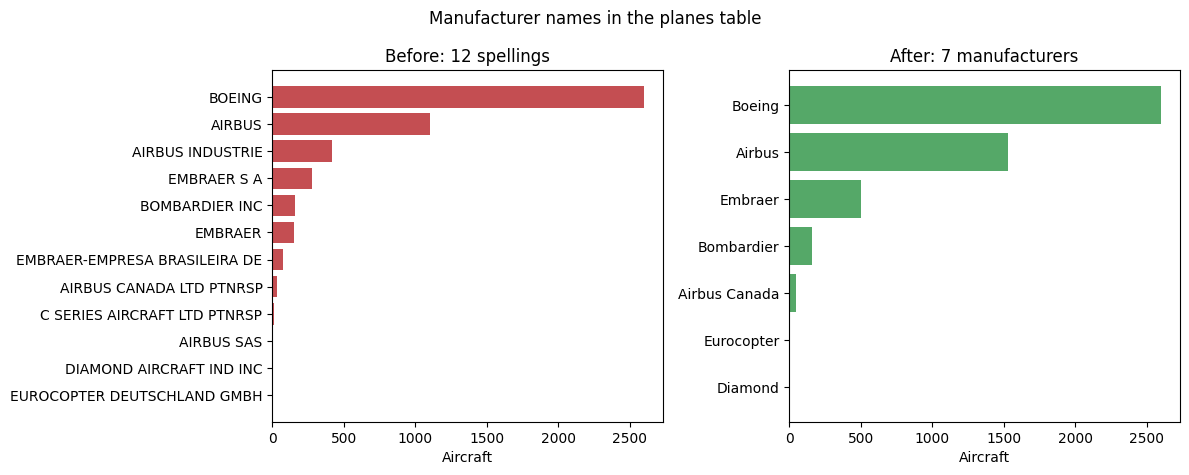

In [60]:
before = planes_raw["manufacturer"].value_counts().sort_values()
after = planes["manufacturer"].value_counts().sort_values()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))

axes[0].barh(before.index, before.values, color="#C44E52")
axes[0].set_title(f"Before: {len(before)} spellings")
axes[0].set_xlabel("Aircraft")

axes[1].barh(after.index, after.values, color="#55A868")
axes[1].set_title(f"After: {len(after)} manufacturers")
axes[1].set_xlabel("Aircraft")

fig.suptitle("Manufacturer names in the planes table")
fig.tight_layout()
fig.savefig(IMAGES / "02_manufacturer_names.png", dpi=150)
plt.show()

Step 2: fix the year, drop `speed`, and give two columns clearer names.

`Int64` (capital I) is the pandas whole-number type that can also hold missing values. The ordinary `int64`
cannot, which is why pandas had fallen back to decimals.

In [61]:
planes["year"] = planes["year"].astype("Int64")      # 2020.0 -> 2020, missing stays missing
planes = planes.drop(columns=["speed"])              # 0 on every row
planes = planes.rename(columns={
    "year": "year_manufactured",
    "type": "aircraft_type",
    "engine": "engine_type",
})

print("Missing year before:", planes_raw["year"].isna().sum(), "  after:", planes["year_manufactured"].isna().sum())
planes.head()

Missing year before: 89   after: 89


,tailnum,year_manufactured,aircraft_type,manufacturer,model,engines,seats,engine_type
0,N101DQ,2020,Fixed wing multi engine,Airbus,A321-211,2,199,Turbo-fan
1,N101DU,2018,Fixed wing multi engine,Airbus Canada,BD-500-1A10,2,133,Turbo-fan
2,N101HQ,2007,Fixed wing multi engine,Embraer,ERJ 170-200 LR,2,80,Turbo-fan
3,N101NN,2013,Fixed wing multi engine,Airbus,A321-231,2,379,Turbo-fan
4,N102DN,2020,Fixed wing multi engine,Airbus,A321-211,2,199,Turbo-fan


### 3.3 Airports

Turn the disguised and impossible values into real missing values, then rename.
`.loc[rows, column] = value` changes only the rows that match the condition.

In [62]:
airports = airports_raw.copy()

# dst code 'U' means unknown, and 'E' (European) is impossible for the Californian airport EMT
airports.loc[airports["dst"] == "U", "dst"] = np.nan
airports.loc[airports["faa"] == "EMT", "dst"] = np.nan

# RHV: positive offset for a Californian airport. OEL: US offset but coordinates in Russia.
airports.loc[airports["faa"] == "RHV", "tz"] = np.nan
airports.loc[airports["faa"] == "OEL", ["tz", "dst"]] = np.nan

airports["tz"] = airports["tz"].astype("Int64")       # offsets are whole hours

# Some coordinates carry 14 meaningless decimals (-176.64599609375). Six decimals is about 10 cm on the ground.
airports["lat"] = airports["lat"].round(6)
airports["lon"] = airports["lon"].round(6)

airports = airports.rename(columns={
    "name": "airport_name",
    "alt": "alt_ft",
    "tz": "utc_offset_hours",
})

In [63]:
before_after = pd.DataFrame({
    "missing_before": airports_raw[["tz", "dst", "tzone"]].isna().sum().values,
    "missing_after": airports[["utc_offset_hours", "dst", "tzone"]].isna().sum().values,
}, index=["tz / utc_offset_hours", "dst", "tzone"])
print(before_after)
print()
print("dst codes after cleaning:", airports["dst"].value_counts().to_dict())

                       missing_before  missing_after
tz / utc_offset_hours              48             50
dst                                48             71
tzone                             119            119

dst codes after cleaning: {'A': 1158, 'N': 26}


Missing counts go *up* here, on purpose: wrong or unknown values that were pretending to be data are now honestly missing.

### 3.4 Weather

Drop the fake gust column and the redundant date parts, convert `time_hour` to a real datetime, and put the
unit into each column name so nobody has to guess between Fahrenheit and Celsius.

In [64]:
weather = weather_raw.copy()

weather["time_hour"] = pd.to_datetime(weather["time_hour"])
weather = weather.drop(columns=["year", "month", "day", "hour", "wind_gust"])

weather = weather.rename(columns={
    "temp": "temp_f",
    "dewp": "dewpoint_f",
    "humid": "humidity_pct",
    "wind_dir": "wind_dir_deg",
    "wind_speed": "wind_speed_mph",
    "precip": "precip_in",
    "pressure": "pressure_mb",
    "visib": "visibility_miles",
})

weather["wind_dir_deg"] = weather["wind_dir_deg"].astype("Int64")     # directions are whole degrees
weather["wind_speed_mph"] = weather["wind_speed_mph"].round(2)        # 4.60312 -> 4.6; the source is whole knots

# Put the key columns first and sort by them
weather = weather[["origin", "time_hour", "temp_f", "dewpoint_f", "humidity_pct", "wind_dir_deg",
                   "wind_speed_mph", "precip_in", "pressure_mb", "visibility_miles"]]
weather = weather.sort_values(["origin", "time_hour"]).reset_index(drop=True)

print("Columns before:", weather_raw.shape[1], "  after:", weather.shape[1])
print("Rows before:   ", len(weather_raw), "  after:", len(weather))
weather.head()

Columns before: 15   after: 10
Rows before:    26207   after: 26207


,origin,time_hour,temp_f,dewpoint_f,humidity_pct,wind_dir_deg,wind_speed_mph,precip_in,pressure_mb,visibility_miles
0,EWR,2023-01-01 00:00:00,52.0,51.0,96.73,220,2.30,0.0100,1009.8,0.5
1,EWR,2023-01-01 01:00:00,53.0,51.0,92.89,210,2.30,0.0100,1009.0,2.5
2,EWR,2023-01-01 02:00:00,53.0,52.0,96.03,0,0.00,0.0100,1008.4,2.5
3,EWR,2023-01-01 03:00:00,54.0,52.0,92.92,210,5.75,0.0100,1007.9,3.0
4,EWR,2023-01-01 04:00:00,54.0,52.0,92.92,250,8.06,0.0001,1007.1,5.0


### 3.5 Flights

This is the main table, so it is cleaned in small steps.

**Step 1: surrogate key and date.** `flight_id` simply numbers the rows 1, 2, 3... in the order they were delivered.

In [65]:
flights = flights_raw.copy()

flights.insert(0, "flight_id", range(1, len(flights) + 1))

# pd.to_datetime can build a date from columns named year, month and day
flights["flight_date"] = pd.to_datetime(flights[["year", "month", "day"]])

flights[["flight_id", "year", "month", "day", "flight_date"]].head(3)

,flight_id,year,month,day,flight_date
0,1,2023,1,1,2023-01-01
1,2,2023,1,1,2023-01-01
2,3,2023,1,1,2023-01-01


**Step 2: flight status.** The rules, taken from the missing-value patterns in section 2.4:

| flight_status | Rule |
|---|---|
| `cancelled` | `dep_time` is missing |
| `diverted_or_incomplete` | `dep_time` is present but `arr_delay` is missing |
| `completed` | everything else (departure and arrival delay both recorded) |

`np.select` checks the conditions in order and uses the first one that is true.

In [66]:
conditions = [
    flights["dep_time"].isna(),
    flights["dep_time"].notna() & flights["arr_delay"].isna(),
]
labels = ["cancelled", "diverted_or_incomplete"]

flights["flight_status"] = np.select(conditions, labels, default="completed")

status_counts = flights["flight_status"].value_counts()
status_share = (status_counts / len(flights) * 100).round(2)
pd.DataFrame({"flights": status_counts, "percent": status_share})

,flights,percent
flight_status,,
completed,422818,97.12
cancelled,10738,2.47
diverted_or_incomplete,1796,0.41


### Chart 3: flight status

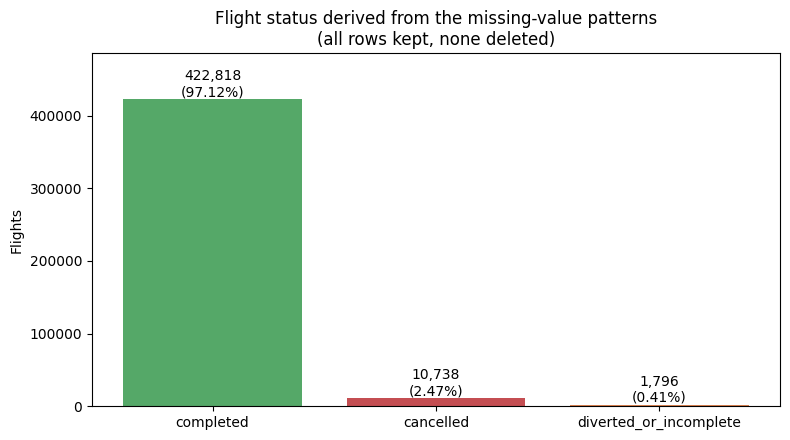

In [67]:
order = ["completed", "cancelled", "diverted_or_incomplete"]
colors = ["#55A868", "#C44E52", "#DD8452"]

fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.bar(order, status_counts[order], color=colors)

for bar, status in zip(bars, order):
    label = f"{status_counts[status]:,}\n({status_share[status]:.2f}%)"
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height(), label, ha="center", va="bottom")

ax.set_ylabel("Flights")
ax.set_ylim(0, status_counts.max() * 1.15)
ax.set_title("Flight status derived from the missing-value patterns\n(all rows kept, none deleted)")
fig.tight_layout()
fig.savefig(IMAGES / "03_flight_status.png", dpi=150)
plt.show()

**Step 3: scheduled departure datetime.** Date plus the scheduled clock time. `pd.to_timedelta(..., unit="m")`
turns a number of minutes into a duration that can be added to a date.

In [68]:
sched_dep_minutes = hhmm_to_minutes(flights["sched_dep_time"])
flights["sched_dep_datetime"] = flights["flight_date"] + pd.to_timedelta(sched_dep_minutes, unit="m")

flights[["flight_date", "sched_dep_time", "sched_dep_datetime"]].head(3)

,flight_date,sched_dep_time,sched_dep_datetime
0,2023-01-01,2038,2023-01-01 20:38:00
1,2023-01-01,2300,2023-01-01 23:00:00
2,2023-01-01,2344,2023-01-01 23:44:00


**Step 4: actual departure datetime.** Uses the rule from section 2.3:

1. compare `dep_delay` with the clock difference to find the day offset (0 = same day, 1 = next day);
2. actual departure = scheduled date + day offset + actual clock time.

A `dep_time` of 2400 becomes 1,440 minutes, and date + 1,440 minutes is 00:00 the next day, so the midnight
case needs no special handling. Cancelled flights have no `dep_time`, so their result stays missing (shown as `NaT`,
"not a time").

In [69]:
dep_minutes = hhmm_to_minutes(flights["dep_time"])                 # missing for cancelled flights

unexplained_minutes = flights["dep_delay"] - (dep_minutes - sched_dep_minutes)
day_offset = (unexplained_minutes / 1440).round()                  # 0 or 1 (missing for cancelled)

flights["actual_dep_datetime"] = (flights["flight_date"]
                                  + pd.to_timedelta(day_offset, unit="D")
                                  + pd.to_timedelta(dep_minutes, unit="m"))

print("Day offsets used:", day_offset.value_counts().to_dict())

Day offsets used: {0.0: 422205, 1.0: 2409}


Before/after check on three kinds of row: a next-day departure, a 2400 departure and a cancelled flight.

In [70]:
show = ["flight_date", "sched_dep_time", "dep_time", "dep_delay", "sched_dep_datetime", "actual_dep_datetime"]

example_rows = pd.concat([
    flights[day_offset == 1].head(2),
    flights[flights["dep_time"] == 2400].head(2),
    flights[flights["flight_status"] == "cancelled"].head(2),
])
example_rows[show]

,flight_date,sched_dep_time,dep_time,dep_delay,sched_dep_datetime,actual_dep_datetime
0,2023-01-01,2038,1.0,203.0,2023-01-01 20:38:00,2023-01-02 00:01:00
1,2023-01-01,2300,18.0,78.0,2023-01-01 23:00:00,2023-01-02 00:18:00
10379,2023-01-10,2245,2400.0,75.0,2023-01-10 22:45:00,2023-01-11 00:00:00
39862,2023-02-03,2149,2400.0,131.0,2023-02-03 21:49:00,2023-02-04 00:00:00
860,2023-01-01,2245,NaN,NaN,2023-01-01 22:45:00,NaT
861,2023-01-01,1655,NaN,NaN,2023-01-01 16:55:00,NaT


**Step 5: arrival times.** Arrival clock times are in the *destination's* local time, and the file does not
give the arrival date. Working out a full arrival datetime would need a time-zone conversion for each of the 118
destinations, which adds assumptions. The arrival delay in minutes is already provided, which is what most
analysis needs.

So the arrival columns become proper `TIME` values (`HH:MM:SS` text that MySQL loads directly), and 2400 becomes
`00:00:00`.

In [71]:
def hhmm_to_time_text(hhmm):
    # Turn 517 into '05:17:00'. 2400 becomes '00:00:00'. Missing values stay missing.
    hhmm = hhmm.astype("Int64")                   # whole numbers that allow missing values
    hours = (hhmm // 100) % 24                    # % 24 turns hour 24 into hour 0
    minutes = hhmm % 100
    text = hours.astype("string").str.zfill(2) + ":" + minutes.astype("string").str.zfill(2) + ":00"
    return text                                   # zfill(2) pads with a leading zero: '5' -> '05'

flights["sched_arr_time_clean"] = hhmm_to_time_text(flights["sched_arr_time"])
flights["actual_arr_time"] = hhmm_to_time_text(flights["arr_time"])

arr_examples = pd.concat([flights.head(2), flights[flights["arr_time"] == 2400].head(2)])
arr_examples[["sched_arr_time", "sched_arr_time_clean", "arr_time", "actual_arr_time"]]

,sched_arr_time,sched_arr_time_clean,arr_time,actual_arr_time
0,3,00:03:00,328.0,03:28:00
1,135,01:35:00,228.0,02:28:00
10364,2359,23:59:00,2400.0,00:00:00
12826,2253,22:53:00,2400.0,00:00:00


**Step 6: tail numbers.** Add the missing `N` to the Allegiant tail numbers found in section 2.6.

In [72]:
needs_prefix = flights["tailnum"].notna() & ~flights["tailnum"].fillna("").str.startswith("N")
print("Rows to fix:", needs_prefix.sum(), "  example before:", flights.loc[needs_prefix, "tailnum"].iloc[0])

flights.loc[needs_prefix, "tailnum"] = "N" + flights.loc[needs_prefix, "tailnum"]

print("Example after:", flights.loc[needs_prefix, "tailnum"].iloc[0])
print("Tail numbers not starting with N after the fix:", (flights["tailnum"].notna() & ~flights["tailnum"].fillna("").str.startswith("N")).sum())

Rows to fix: 668   example before: 203NV
Example after: N203NV
Tail numbers not starting with N after the fix: 0


**Step 7: types, names and column order.** Whole-number columns become `Int64`, units go into the names,
`flight` becomes `flight_number`, `time_hour` becomes a real datetime, and the columns that have been replaced
are left out of the final selection.

In [73]:
flights["time_hour"] = pd.to_datetime(flights["time_hour"])

flights = flights.rename(columns={
    "flight": "flight_number",
    "dep_delay": "dep_delay_min",
    "arr_delay": "arr_delay_min",
    "air_time": "air_time_min",
    "distance": "distance_miles",
})

for column in ["dep_delay_min", "arr_delay_min", "air_time_min", "distance_miles"]:
    flights[column] = flights[column].astype("Int64")

# The old sched_arr_time number is replaced by the TIME version
flights = flights.drop(columns=["sched_arr_time"])
flights = flights.rename(columns={"sched_arr_time_clean": "sched_arr_time"})

final_columns = [
    "flight_id", "flight_date", "carrier", "flight_number", "tailnum", "origin", "dest", "flight_status",
    "sched_dep_datetime", "actual_dep_datetime", "dep_delay_min",
    "sched_arr_time", "actual_arr_time", "arr_delay_min",
    "air_time_min", "distance_miles", "time_hour",
]
dropped = [c for c in flights.columns if c not in final_columns]
print("Columns left out because they were replaced or redundant:", dropped)

flights = flights[final_columns]
flights.head()

Columns left out because they were replaced or redundant: ['year', 'month', 'day', 'dep_time', 'sched_dep_time', 'arr_time', 'hour', 'minute']


,flight_id,flight_date,carrier,flight_number,tailnum,origin,dest,flight_status,sched_dep_datetime,actual_dep_datetime,dep_delay_min,sched_arr_time,actual_arr_time,arr_delay_min,air_time_min,distance_miles,time_hour
0,1,2023-01-01,UA,628,N25201,EWR,SMF,completed,2023-01-01 20:38:00,2023-01-02 00:01:00,203,00:03:00,03:28:00,205,367,2500,2023-01-01 20:00:00
1,2,2023-01-01,DL,393,N830DN,JFK,ATL,completed,2023-01-01 23:00:00,2023-01-02 00:18:00,78,01:35:00,02:28:00,53,108,760,2023-01-01 23:00:00
2,3,2023-01-01,B6,371,N807JB,JFK,BQN,completed,2023-01-01 23:44:00,2023-01-02 00:31:00,47,04:26:00,05:00:00,34,190,1576,2023-01-01 23:00:00
3,4,2023-01-01,B6,1053,N265JB,JFK,CHS,completed,2023-01-01 21:40:00,2023-01-02 00:33:00,173,23:52:00,02:38:00,166,108,636,2023-01-01 21:00:00
4,5,2023-01-01,UA,219,N17730,EWR,DTW,completed,2023-01-01 20:48:00,2023-01-02 00:36:00,228,22:52:00,02:23:00,211,80,488,2023-01-01 20:00:00


In [74]:
print("Rows before:", len(flights_raw), "  after:", len(flights))
print("Columns before:", flights_raw.shape[1], "  after:", flights.shape[1])
profile(flights)

Rows before: 435352   after: 435352
Columns before: 19   after: 17


,dtype,missing,missing_pct,distinct
flight_id,int64,0,0.00,435352
flight_date,datetime64[ns],0,0.00,365
carrier,object,0,0.00,14
flight_number,int64,0,0.00,1972
tailnum,object,1913,0.44,5117
origin,object,0,0.00,3
dest,object,0,0.00,118
flight_status,object,0,0.00,3
sched_dep_datetime,datetime64[ns],0,0.00,155503
actual_dep_datetime,datetime64[ns],10738,2.47,249562


## 4. Validation

Cleaning is only finished when the result can be *proved* to follow the rules. Each `assert` below stops the
notebook with an error if its rule is broken. If the whole section runs, every rule holds.

### 4.1 Nothing was lost

In [75]:
assert len(flights) == len(flights_raw) == 435352
assert len(airlines) == len(airlines_raw)
assert len(airports) == len(airports_raw)
assert len(planes) == len(planes_raw)
assert len(weather) == len(weather_raw)

# The values that were not supposed to change did not change
assert flights["dep_delay_min"].isna().sum() == flights_raw["dep_delay"].isna().sum()
assert flights["arr_delay_min"].isna().sum() == flights_raw["arr_delay"].isna().sum()
assert flights["dep_delay_min"].sum() == flights_raw["dep_delay"].sum()
assert flights["arr_delay_min"].sum() == flights_raw["arr_delay"].sum()
print("Row counts and delay totals are unchanged.")

Row counts and delay totals are unchanged.


### 4.2 Primary keys are unique and never missing

In [76]:
assert flights["flight_id"].is_unique and flights["flight_id"].notna().all()
assert airlines["carrier"].is_unique and airlines["carrier"].notna().all()
assert airports["faa"].is_unique and airports["faa"].notna().all()
assert planes["tailnum"].is_unique and planes["tailnum"].notna().all()
assert not weather.duplicated(["origin", "time_hour"]).any()
assert weather[["origin", "time_hour"]].notna().all().all()
print("All primary keys are unique and complete.")

All primary keys are unique and complete.


### 4.3 Foreign keys are valid, or are documented exceptions with a known size

In [77]:
# Strict foreign keys: no exceptions allowed
assert flights["carrier"].isin(airlines["carrier"]).all()
assert flights["origin"].isin(airports["faa"]).all()
assert flights["dest"].isin(airports["faa"]).all()
assert weather["origin"].isin(airports["faa"]).all()

# Documented exception 1: tail numbers that are not in planes
has_tail = flights["tailnum"].notna()
no_plane = has_tail & ~flights["tailnum"].isin(planes["tailnum"])
print(f"Flights whose tailnum is not in planes: {no_plane.sum():,} ({flights.loc[no_plane, 'tailnum'].nunique()} aircraft)")
assert no_plane.sum() == tail_orphans                 # same number as in the audit: cleaning did not make it worse

# Documented exception 2: flights with no weather row
weather_keys = weather[["origin", "time_hour"]].copy()
weather_keys["has_weather"] = True
check = flights[["origin", "time_hour"]].merge(weather_keys, on=["origin", "time_hour"], how="left")
no_weather = check["has_weather"].isna()
print(f"Flights with no weather row:            {no_weather.sum():,}")
assert no_weather.sum() == weather_orphans
assert len(check) == len(flights)                     # the join did not duplicate any flight

print("Strict foreign keys are valid; the two exceptions match the audit.")

Flights whose tailnum is not in planes: 9,371 (277 aircraft)


Flights with no weather row:            826
Strict foreign keys are valid; the two exceptions match the audit.


When are the flights without weather? This confirms they fall exactly in the weather gap found in section 2.10.

In [78]:
flights[no_weather.values].groupby(["origin", "flight_date"]).size()

origin  flight_date
EWR     2023-12-31     302
JFK     2023-12-31     270
LGA     2023-05-02       3
        2023-12-31     251
dtype: int64

### 4.4 Status rules and datetimes are consistent

In [79]:
cancelled = flights["flight_status"] == "cancelled"
completed = flights["flight_status"] == "completed"
incomplete = flights["flight_status"] == "diverted_or_incomplete"

# Only the three allowed values, and every flight has one
assert set(flights["flight_status"]) == {"completed", "cancelled", "diverted_or_incomplete"}
assert cancelled.sum() + completed.sum() + incomplete.sum() == len(flights)

# Cancelled flights have no actual times or delays at all
cancelled_columns = ["actual_dep_datetime", "dep_delay_min", "actual_arr_time", "arr_delay_min", "air_time_min"]
assert flights.loc[cancelled, cancelled_columns].isna().all().all()

# Completed flights have every one of them
assert flights.loc[completed, cancelled_columns].notna().all().all()

# Diverted/incomplete flights departed but have no arrival delay or air time
assert flights.loc[incomplete, ["actual_dep_datetime", "dep_delay_min"]].notna().all().all()
assert flights.loc[incomplete, ["arr_delay_min", "air_time_min"]].isna().all().all()

# Scheduled fields are never missing
assert flights[["flight_date", "sched_dep_datetime", "sched_arr_time", "distance_miles", "time_hour"]].notna().all().all()
print("Status rules hold for every row.")

Status rules hold for every row.


In [80]:
departed = flights[~cancelled]

# 1. The new datetimes must reproduce the delay: actual - scheduled = dep_delay (in minutes)
gap_minutes = (departed["actual_dep_datetime"] - departed["sched_dep_datetime"]).dt.total_seconds() / 60
mismatch = gap_minutes != departed["dep_delay_min"]
print("Departed flights where actual - scheduled differs from dep_delay:", mismatch.sum())

# The only differences allowed are the two daylight-saving flights (exactly one hour)
assert mismatch.sum() == n_dst
assert ((gap_minutes - departed["dep_delay_min"])[mismatch].abs() == 60).all()

# 2. The clock time inside the new datetime must equal the original dep_time (2400 = 00:00)
raw_clock = flights_raw.loc[departed.index, "dep_time"] % 2400
new_clock = departed["actual_dep_datetime"].dt.hour * 100 + departed["actual_dep_datetime"].dt.minute
assert (raw_clock == new_clock).all()

# 3. time_hour is the scheduled departure rounded down to the hour, and everything is inside 2023 (+1 day)
assert (flights["time_hour"] == flights["sched_dep_datetime"].dt.floor("h")).all()
assert flights["sched_dep_datetime"].dt.year.eq(2023).all()
assert departed["actual_dep_datetime"].max() < pd.Timestamp("2024-01-02")
print("Datetimes agree with the original clock times and delays.")

Departed flights where actual - scheduled differs from dep_delay: 2
Datetimes agree with the original clock times and delays.


### 4.5 No impossible values

In [81]:
# Flights
assert (flights["distance_miles"] > 0).all()
assert (flights["air_time_min"].dropna() > 0).all()
assert (flights["origin"] != flights["dest"]).all()
assert flights["origin"].isin(["EWR", "JFK", "LGA"]).all()
assert flights["tailnum"].dropna().str.match(r"^N[0-9A-Z]{1,5}$").all()          # N + up to 5 letters/digits
assert flights["sched_arr_time"].str.match(r"^([01]\d|2[0-3]):[0-5]\d:00$").all()  # valid 24-hour time
assert flights["actual_arr_time"].dropna().str.match(r"^([01]\d|2[0-3]):[0-5]\d:00$").all()

# Planes
assert planes["manufacturer"].nunique() == 7 and planes["manufacturer"].notna().all()
assert planes["year_manufactured"].dropna().between(1903, 2023).all()
assert "speed" not in planes.columns

# Airports
assert airports["lat"].between(-90, 90).all() and airports["lon"].between(-180, 180).all()
assert airports["utc_offset_hours"].dropna().between(-12, 14).all()
assert (airports.loc[airports["lon"] < -60, "utc_offset_hours"].dropna() < 0).all()   # the Americas are behind UTC
assert airports["dst"].dropna().isin(["A", "N"]).all()

# Weather
assert weather["humidity_pct"].dropna().between(0, 100).all()
assert weather["wind_dir_deg"].dropna().between(0, 360).all()
assert (weather["wind_speed_mph"].dropna() >= 0).all()
assert (weather["precip_in"] >= 0).all()
assert (weather["dewpoint_f"].dropna() <= weather["temp_f"].dropna()).all()   # dew point cannot exceed temperature
assert weather["time_hour"].dt.year.eq(2023).all()
print("No impossible values found in any cleaned table.")

No impossible values found in any cleaned table.


### Chart 4: how well do the flights link to the other tables?

The share of the 435,352 flights that find a matching row in each lookup table.

In [82]:
total = len(flights)
link_summary = pd.DataFrame({
    "link": ["carrier -> airlines", "origin -> airports", "dest -> airports",
             "tailnum -> planes", "origin + hour -> weather"],
    "matched": [
        flights["carrier"].isin(airlines["carrier"]).sum(),
        flights["origin"].isin(airports["faa"]).sum(),
        flights["dest"].isin(airports["faa"]).sum(),
        flights["tailnum"].isin(planes["tailnum"]).sum(),      # a missing tailnum counts as not matched
        (~no_weather).sum(),
    ],
})
link_summary["not_matched"] = total - link_summary["matched"]
link_summary["matched_pct"] = (link_summary["matched"] / total * 100).round(2)
link_summary

,link,matched,not_matched,matched_pct
0,carrier -> airlines,435352,0,100.00
1,origin -> airports,435352,0,100.00
2,dest -> airports,435352,0,100.00
3,tailnum -> planes,424068,11284,97.41
4,origin + hour -> weather,434526,826,99.81


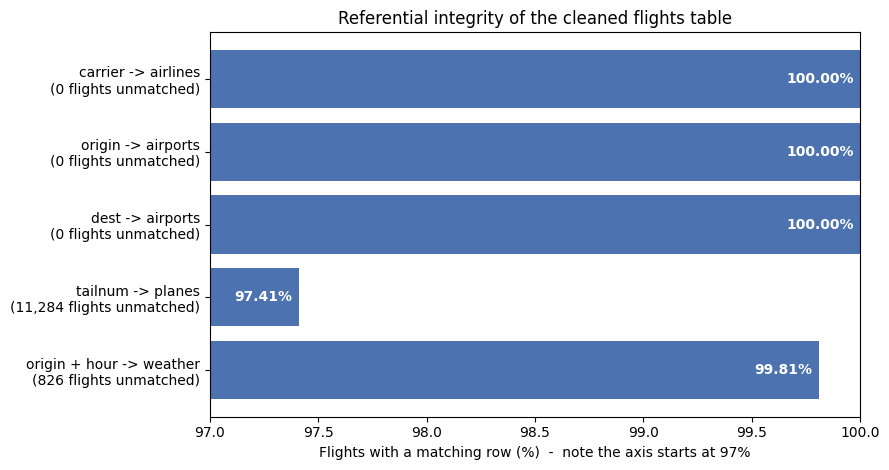

In [83]:
plot_data = link_summary.iloc[::-1]          # reverse so the first link is drawn at the top

# Put the number of unmatched flights into each bar's label
bar_labels = [f"{link}\n({missing:,} flights unmatched)" for link, missing in zip(plot_data["link"], plot_data["not_matched"])]

fig, ax = plt.subplots(figsize=(9, 4.8))
bars = ax.barh(bar_labels, plot_data["matched_pct"], color="#4C72B0")

for bar, pct in zip(bars, plot_data["matched_pct"]):
    ax.text(bar.get_width() - 0.03, bar.get_y() + bar.get_height() / 2, f"{pct:.2f}%",
            va="center", ha="right", color="white", fontweight="bold")

ax.set_xlim(97, 100)                         # zoomed in: all values are above 97%
ax.set_xlabel("Flights with a matching row (%)  -  note the axis starts at 97%")
ax.set_title("Referential integrity of the cleaned flights table")
fig.tight_layout()
fig.savefig(IMAGES / "04_referential_integrity.png", dpi=150)
plt.show()

The `tailnum -> planes` figure counts both kinds of unmatched flight: tail numbers that are not in planes, and
cancelled flights with no tail number at all.

## 5. Export

Rules for the files, so they load cleanly into MySQL:

- UTF-8 text, comma separated, one header row, Unix line endings (`\n`);
- missing values are **empty fields** (nothing between the commas);
- dates as `YYYY-MM-DD`, datetimes as `YYYY-MM-DD HH:MM:SS`, times as `HH:MM:SS`;
- the big flights table goes into a zip to stay under GitHub's file-size limit.

In [84]:
flights_out = flights.copy()
# Write the date without a time part
flights_out["flight_date"] = flights_out["flight_date"].dt.strftime("%Y-%m-%d")

csv_options = {
    "index": False,
    "na_rep": "",                              # missing value -> empty field
    "date_format": "%Y-%m-%d %H:%M:%S",        # format for the datetime columns
    "encoding": "utf-8",
    "lineterminator": "\n",                    # same line ending on Windows, Mac and Linux
}

airlines.to_csv(PROCESSED / "airlines_clean.csv", **csv_options)
airports.to_csv(PROCESSED / "airports_clean.csv", **csv_options)
planes.to_csv(PROCESSED / "planes_clean.csv", **csv_options)
weather.to_csv(PROCESSED / "weather_clean.csv", **csv_options)
audit_table.to_csv(PROCESSED / "cleaning_log.csv", **csv_options)

# One CSV inside a zip file
flights_out.to_csv(PROCESSED / "flights_clean.zip",
                   compression={"method": "zip", "archive_name": "flights_clean.csv"},
                   **csv_options)

for path in sorted(PROCESSED.iterdir()):
    print(f"{path.name:22s} {path.stat().st_size / 1_000_000:6.2f} MB")

airlines_clean.csv       0.00 MB
airports_clean.csv       0.10 MB
cleaning_log.csv         0.01 MB
flights_clean.zip       13.02 MB
planes_clean.csv         0.33 MB
weather_clean.csv        1.69 MB


### Read the exported files back

A final check that the files on disk hold what was intended: same row counts, and the missing values survived as missing.

In [85]:
flights_check = pd.read_csv(PROCESSED / "flights_clean.zip", parse_dates=["flight_date", "sched_dep_datetime", "actual_dep_datetime", "time_hour"])
planes_check = pd.read_csv(PROCESSED / "planes_clean.csv")
airports_check = pd.read_csv(PROCESSED / "airports_clean.csv")
weather_check = pd.read_csv(PROCESSED / "weather_clean.csv", parse_dates=["time_hour"])
airlines_check = pd.read_csv(PROCESSED / "airlines_clean.csv")

assert len(flights_check) == len(flights)
assert flights_check["flight_id"].is_unique
assert flights_check["actual_dep_datetime"].isna().sum() == n_cancelled
assert flights_check["arr_delay_min"].isna().sum() == n_cancelled + n_incomplete
assert (flights_check["sched_dep_datetime"] == flights["sched_dep_datetime"]).all()
assert len(planes_check) == len(planes) and planes_check["year_manufactured"].isna().sum() == 89
assert len(airports_check) == len(airports)
assert len(weather_check) == len(weather)
assert len(airlines_check) == len(airlines)
print("Exported files read back correctly.")

Exported files read back correctly.


### Column summary of the cleaned tables

This summary is the basis of the data dictionary in `data/README.md`: for every column, the type, whether it can
be missing, and the longest text or the smallest and largest value (useful for choosing database column sizes).

In [86]:
def column_summary(table):
    rows = []
    for column in table.columns:
        values = table[column].dropna()
        is_text = values.map(lambda v: isinstance(v, str)).all()
        if is_text:
            detail = f"max length {values.str.len().max()}"
        else:
            detail = f"{values.min()} to {values.max()}"
        rows.append({
            "column": column,
            "dtype": str(table[column].dtype),
            "missing": int(table[column].isna().sum()),
            "distinct": int(table[column].nunique()),
            "range_or_length": detail,
        })
    return pd.DataFrame(rows)

clean_tables = {"flights": flights, "airlines": airlines, "airports": airports, "planes": planes, "weather": weather}

for name, table in clean_tables.items():
    print(f"--- {name}: {len(table):,} rows ---")
    print(column_summary(table).to_string(index=False))
    print()

--- flights: 435,352 rows ---


             column          dtype  missing  distinct                            range_or_length
          flight_id          int64        0    435352                                1 to 435352
        flight_date datetime64[ns]        0       365 2023-01-01 00:00:00 to 2023-12-31 00:00:00
            carrier         object        0        14                               max length 2
      flight_number          int64        0      1972                                  1 to 1972
            tailnum         object     1913      5117                               max length 6
             origin         object        0         3                               max length 3
               dest         object        0       118                               max length 3
      flight_status         object        0         3                              max length 22
 sched_dep_datetime datetime64[ns]        0    155503 2023-01-01 05:00:00 to 2023-12-31 23:25:00
actual_dep_datetime datetime64

## Summary

Key numbers, all calculated above:

In [87]:
print(f"Flights in / out:                         {len(flights_raw):,} / {len(flights):,} (no rows deleted)")
print(f"Issues recorded in the cleaning log:      {len(audit_table)}")
print(f"Completed flights:                        {status_counts['completed']:,} ({status_share['completed']}%)")
print(f"Cancelled flights (kept, flagged):        {status_counts['cancelled']:,} ({status_share['cancelled']}%)")
print(f"Diverted or incomplete (kept, flagged):   {status_counts['diverted_or_incomplete']:,} ({status_share['diverted_or_incomplete']}%)")
print(f"Departures moved to the next day:         {n_next_day:,}")
print(f"2400 values converted (dep / arr):        {n_dep_2400} / {n_arr_2400}")
print(f"Tail numbers given the N prefix:          {n_no_prefix} flights")
print(f"Flights whose tailnum is not in planes:   {tail_orphans:,} ({tail_orphans_distinct} aircraft)")
print(f"Flights with no weather row:              {weather_orphans:,}")
print(f"Missing weather airport-hours:            {n_missing_hours}")
print(f"Manufacturer spellings before / after:    {planes_raw['manufacturer'].nunique()} / {planes['manufacturer'].nunique()}")
print(f"Columns before / after  flights:          {flights_raw.shape[1]} / {flights.shape[1]}")
print(f"                        planes:           {planes_raw.shape[1]} / {planes.shape[1]}")
print(f"                        weather:          {weather_raw.shape[1]} / {weather.shape[1]}")
print(f"                        airports:         {airports_raw.shape[1]} / {airports.shape[1]}")
print(f"Values imputed (filled in by estimate):   0")

Flights in / out:                         435,352 / 435,352 (no rows deleted)
Issues recorded in the cleaning log:      47
Completed flights:                        422,818 (97.12%)
Cancelled flights (kept, flagged):        10,738 (2.47%)
Diverted or incomplete (kept, flagged):   1,796 (0.41%)
Departures moved to the next day:         2,409
2400 values converted (dep / arr):        27 / 198
Tail numbers given the N prefix:          668 flights
Flights whose tailnum is not in planes:   9,371 (277 aircraft)
Flights with no weather row:              826
Missing weather airport-hours:            73
Manufacturer spellings before / after:    12 / 7
Columns before / after  flights:          19 / 17
                        planes:           9 / 8
                        weather:          15 / 10
                        airports:         8 / 8
Values imputed (filled in by estimate):   0


**What the client receives**

- five cleaned tables in `data/processed/`, with unique keys, valid links (or documented exceptions) and no impossible values;
- `cleaning_log.csv`: every issue, the number of rows affected and the decision;
- a data dictionary in `data/README.md` describing every column.

No rows were deleted and no values were imputed. Where the data could not be trusted, it was flagged, set to
missing, or documented, never guessed.